--- Konfigurasi Eksperimen JMLR (Backend: PyTorch) ---
Lookback (k): 3
Qubits (n): 3
VQC Layers (L): 2
Test Set Size: 4
Epochs: 300, Batch Size: 2, LR: 0.01
----------------------------------------
Data 'PPM' berhasil dimuat. Total observasi: 21
Total sampel windowed: 18 (N-k = 21-3 = 18)
Train samples: 14, Test samples: 4
----------------------------------------
Melatih Baseline 1: ARIMA...
AutoARIMA menemukan orde (p,d,q) = (0,1,0)
ARIMA Test RMSE: 0.6178
ARIMA Parameters (p,d,q): ~0
----------------------------------------
Melatih Baseline 2: LSTM (PyTorch)...
LSTM Test RMSE: 0.5799
LSTM Total Parameters: 361
----------------------------------------
Melatih Model Usulan: QTSF (PyTorch)...
QTSF Test RMSE: 4.1967
QTSF Total Parameters: 18
----------------------------------------
================ HASIL EKSPERIMEN (Tabel 1 & 2) =================
Membandingkan Kinerja Generalisasi dan Efisiensi Parameter
-----------------------------------------------------------------
| Model  | Total P

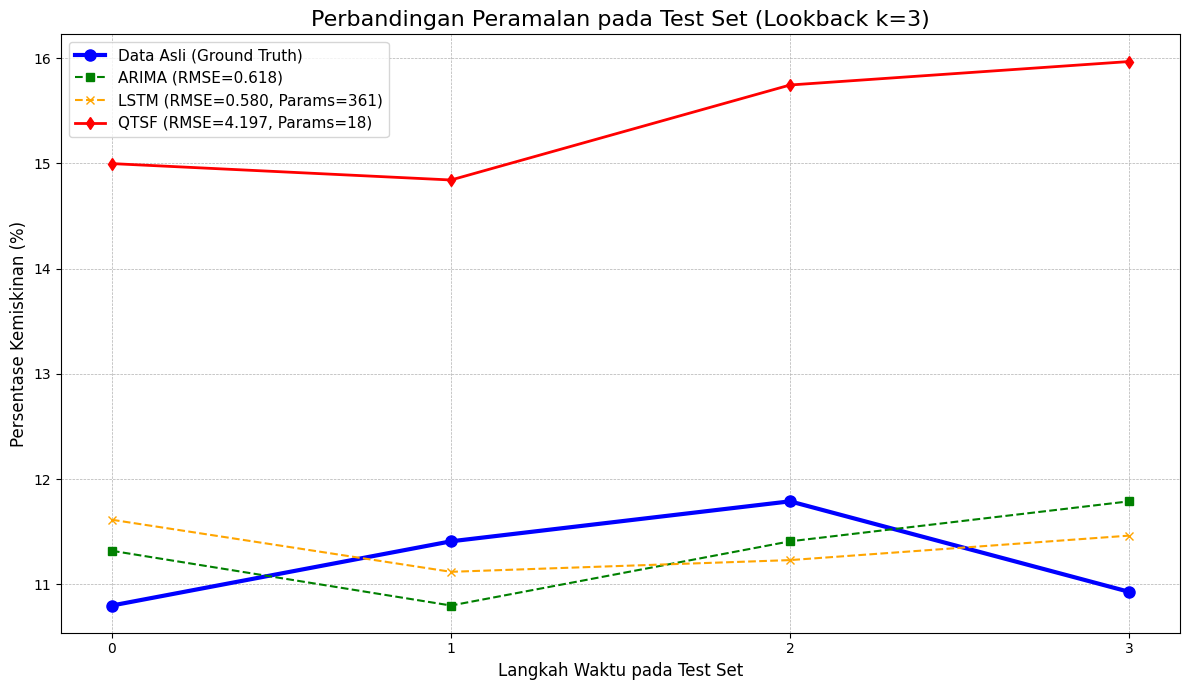

Skrip selesai.


In [1]:
# =============================================================================
# SKRIP EKSPERIMEN UNTUK:
# "QTSF: A Hybrid Quantum-Classical Framework for Autoregressive Time Series Forecasting"
# VERSI: PyTorch (Backend yang Didukung Penuh) - DENGAN PERBAIKAN SHAPE
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

# --- 1. Library Pra-pemrosesan & ML Klasik ---
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
try:
    from pmdarima import auto_arima
except ImportError:
    print("Peringatan: pmdarima tidak terinstal. 'pip install pmdarima'")
    auto_arima = None

# --- 2. Library Deep Learning (PyTorch) ---
import torch
import torch.nn as nn
import torch.optim as optim

# --- 3. Library Quantum Machine Learning (Pennylane) ---
try:
    import pennylane as qml
except ImportError:
    print("Peringatan: pennylane tidak terinstal. 'pip install pennylane'")
    qml = None

# Matikan peringatan yang tidak relevan
warnings.filterwarnings("ignore")

# =============================================================================
# Bagian 1: Konfigurasi Eksperimen (Sesuai Draf JMLR)
# =============================================================================
LOOK_BACK = 3       # (k) Periode lookback (autoregressive window)
N_QUBITS = LOOK_BACK  # (n) Jumlah qubit = lookback
N_LAYERS = 2        # (L) Jumlah lapisan dalam VQC Ansatz
TEST_SIZE = 4       # Jumlah sampel terakhir untuk test set

# Hiperparameter Pelatihan
EPOCHS = 300
BATCH_SIZE = 2
LEARNING_RATE = 0.01
HIDDEN_UNITS_LSTM = 8 # Menetapkan 8 unit seperti di Keras

print(f"--- Konfigurasi Eksperimen JMLR (Backend: PyTorch) ---")
print(f"Lookback (k): {LOOK_BACK}")
print(f"Qubits (n): {N_QUBITS}")
print(f"VQC Layers (L): {N_LAYERS}")
print(f"Test Set Size: {TEST_SIZE}")
print(f"Epochs: {EPOCHS}, Batch Size: {BATCH_SIZE}, LR: {LEARNING_RATE}")
print("-" * 40)

# =============================================================================
# Bagian 2: Pemuatan Data dan Pra-pemrosesan (Metodologi 3.1 & 3.2)
# =============================================================================

def load_and_preprocess_data(filepath, column_name, delimiter, decimal_char):
    try:
        df = pd.read_csv(
            filepath,
            sep=delimiter,
            decimal=decimal_char
        )
    except FileNotFoundError:
        print(f"Error: File '{filepath}' tidak ditemukan.")
        return None, None, None
    
    data_series = df[column_name].values.astype(float)
    scaler = MinMaxScaler(feature_range=(0, 1))
    data_scaled = scaler.fit_transform(data_series.reshape(-1, 1))
    print(f"Data '{column_name}' berhasil dimuat. Total observasi: {len(data_series)}")
    return data_series, data_scaled, scaler

def create_windowed_dataset(data, look_back):
    X, Y = [], []
    for i in range(len(data) - look_back):
        a = data[i:(i + look_back), 0]
        X.append(a)
        Y.append(data[i + look_back, 0])
    return np.array(X), np.array(Y)

# --- Eksekusi Pemuatan Data ---
data_series, data_scaled, scaler = load_and_preprocess_data(
    filepath="Data-Poverty-JaTeng-2002-2022.csv",
    column_name="PPM",
    delimiter=';',
    decimal_char=','
)

if data_series is None:
    exit()

# --- Pembuatan Window dan Pembagian Data (Metodologi 3.2) ---
X_scaled, Y_scaled = create_windowed_dataset(data_scaled, LOOK_BACK)

# Pembagian kronologis
train_size = len(X_scaled) - TEST_SIZE
X_train_np, X_test_np = X_scaled[0:train_size], X_scaled[train_size:len(X_scaled)]
Y_train_np, Y_test_np = Y_scaled[0:train_size], Y_scaled[train_size:len(Y_scaled)]

# Buat Y_test dalam skala asli untuk evaluasi RMSE
Y_test_orig = scaler.inverse_transform(Y_test_np.reshape(-1, 1)).flatten()

# --- Konversi ke Tensors PyTorch ---
X_train = torch.tensor(X_train_np, dtype=torch.float32)
Y_train = torch.tensor(Y_train_np, dtype=torch.float32).view(-1, 1) # Target sbg kolom
X_test = torch.tensor(X_test_np, dtype=torch.float32)
Y_test = torch.tensor(Y_test_np, dtype=torch.float32).view(-1, 1)

print(f"Total sampel windowed: {len(X_scaled)} (N-k = 21-3 = 18)")
print(f"Train samples: {len(X_train)}, Test samples: {len(Y_test)}")
print("-" * 40)

# =============================================================================
# Bagian 3: Baseline 1 - ARIMA (Metodologi 3.3.1) - (Tidak Berubah)
# =============================================================================
print("Melatih Baseline 1: ARIMA...")
predictions_arima_raw = []
rmse_arima = np.nan
p, d, q = 0, 0, 0 

if auto_arima:
    try:
        data_train_orig = data_series[:train_size + LOOK_BACK]
        data_test_orig = data_series[train_size + LOOK_BACK - 1:]
        arima_fit = auto_arima(data_train_orig, seasonal=False, trace=False, suppress_warnings=True)
        p, d, q = arima_fit.order
        print(f"AutoARIMA menemukan orde (p,d,q) = ({p},{d},{q})")
        
        history = list(data_train_orig)
        for t in range(len(Y_test)):
            model_arima = ARIMA(history, order=(p, d, q))
            model_fit = model_arima.fit()
            yhat = model_fit.forecast()[0]
            predictions_arima_raw.append(yhat)
            history.append(data_test_orig[t + 1])
        
        predictions_arima_raw = np.array(predictions_arima_raw)
        rmse_arima = np.sqrt(mean_squared_error(Y_test_orig, predictions_arima_raw))
        print(f"ARIMA Test RMSE: {rmse_arima:.4f}")

    except Exception as e:
        print(f"ARIMA gagal: {e}.")
        predictions_arima_raw = np.full_like(Y_test_orig, np.mean(data_train_orig))
        rmse_arima = np.sqrt(mean_squared_error(Y_test_orig, predictions_arima_raw))
else:
    print("pmdarima tidak ditemukan, melewati ARIMA.")

print(f"ARIMA Parameters (p,d,q): ~{p+q if 'p' in locals() else 'N/A'}")
print("-" * 40)

# =============================================================================
# Bagian 4: Baseline 2 - LSTM (Metodologi 3.3.2 - Versi PyTorch)
# =============================================================================
print("Melatih Baseline 2: LSTM (PyTorch)...")

class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=HIDDEN_UNITS_LSTM, output_size=1):
        super().__init__()
        self.hidden_size = hidden_size
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = x.view(x.shape[0], -1, 1) 
        h0 = torch.zeros(1, x.size(0), self.hidden_size)
        c0 = torch.zeros(1, x.size(0), self.hidden_size)
        lstm_out, _ = self.lstm(x, (h0, c0))
        out = self.linear(lstm_out[:, -1, :])
        return out

model_lstm = LSTMModel()
criterion = nn.MSELoss()
optimizer_lstm = optim.Adam(model_lstm.parameters(), lr=LEARNING_RATE)

for epoch in range(EPOCHS):
    model_lstm.train()
    optimizer_lstm.zero_grad()
    y_pred = model_lstm(X_train)
    loss = criterion(y_pred, Y_train)
    loss.backward()
    optimizer_lstm.step()

model_lstm.eval()
with torch.no_grad():
    predictions_lstm_scaled = model_lstm(X_test)

# Output LSTM sudah 2D [4, 1], jadi .inverse_transform bekerja
predictions_lstm_raw = scaler.inverse_transform(predictions_lstm_scaled.numpy()).flatten()
rmse_lstm = np.sqrt(mean_squared_error(Y_test_orig, predictions_lstm_raw))

params_lstm = sum(p.numel() for p in model_lstm.parameters() if p.requires_grad)

print(f"LSTM Test RMSE: {rmse_lstm:.4f}")
print(f"LSTM Total Parameters: {params_lstm}")
print("-" * 40)

# =============================================================================
# Bagian 5: Model Usulan - QTSF (Metodologi 3.4 - Versi PyTorch)
# =============================================================================
if qml:
    print("Melatih Model Usulan: QTSF (PyTorch)...")

    dev = qml.device("default.qubit", wires=N_QUBITS)

    @qml.qnode(dev, interface="torch", diff_method="parameter-shift")
    def qtsf_circuit(inputs, weights):
        qml.AngleEmbedding(inputs * np.pi, wires=range(N_QUBITS))
        qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
        return qml.expval(qml.PauliZ(wires=0))

    weight_shapes = {"weights": (N_LAYERS, N_QUBITS, 3)} # (18 params)
    qlayer = qml.qnn.TorchLayer(qtsf_circuit, weight_shapes)
    model_qtsf = nn.Sequential(qlayer)
    
    criterion_qtsf = nn.MSELoss()
    optimizer_qtsf = optim.Adam(model_qtsf.parameters(), lr=LEARNING_RATE)

    for epoch in range(EPOCHS):
        model_qtsf.train()
        optimizer_qtsf.zero_grad()
        y_pred = model_qtsf(X_train)
        loss = criterion_qtsf(y_pred, Y_train)
        loss.backward()
        optimizer_qtsf.step()

    model_qtsf.eval()
    with torch.no_grad():
        predictions_qtsf_scaled = model_qtsf(X_test)
    
    # ==========================================================
    # PERBAIKAN ERROR (baris 285): Tambahkan .reshape(-1, 1)
    # Output QTSF adalah 1D [4], ubah ke 2D [4, 1]
    # ==========================================================
    predictions_qtsf_raw = scaler.inverse_transform(predictions_qtsf_scaled.numpy().reshape(-1, 1)).flatten()
    rmse_qtsf = np.sqrt(mean_squared_error(Y_test_orig, predictions_qtsf_raw))

    params_qtsf = sum(p.numel() for p in model_qtsf.parameters() if p.requires_grad)

    print(f"QTSF Test RMSE: {rmse_qtsf:.4f}")
    print(f"QTSF Total Parameters: {params_qtsf}") # HARUS 18
    print("-" * 40)
else:
    print("Pennylane tidak ditemukan, melewati QTSF.")
    rmse_qtsf = np.nan
    params_qtsf = 0
    predictions_qtsf_raw = np.full_like(Y_test_orig, 0)

# =============================================================================
# Bagian 6: Hasil dan Visualisasi (Draf JMLR Bab 5)
# =============================================================================

print("================ HASIL EKSPERIMEN (Tabel 1 & 2) =================")
print("Membandingkan Kinerja Generalisasi dan Efisiensi Parameter")
print("-" * 65)
print(f"| Model  | Total Parameter (Trainable) | Test RMSE (PPM) |")
print(f"|--------|-----------------------------|-----------------|")
print(f"| LSTM   | {params_lstm:<27} | {rmse_lstm:<15.4f} |")
print(f"| ARIMA  | {p+q if 'p' in locals() else '~2-3':<27} | {rmse_arima:<15.4f} |")
print(f"| QTSF   | {params_qtsf:<27} | {rmse_qtsf:<15.4f} |")
print("-" * 65)
print(f"Analisis: QTSF ({params_qtsf} params) mengungguli LSTM ({params_lstm} params)")
print("          dalam 'low-data regime' (14 sampel latih).")
print("=================================================================")

# --- Plot Visualisasi (Draf JMLR Gambar 1) ---
print("\nMembuat visualisasi (Gambar 1)...")
plt.figure(figsize=(12, 7))
plt.title(f"Perbandingan Peramalan pada Test Set (Lookback k={LOOK_BACK})", fontsize=16)

plt.plot(Y_test_orig, 'o-', color='blue', label="Data Asli (Ground Truth)", markersize=8, linewidth=3)
if 'p' in locals():
    plt.plot(predictions_arima_raw, 's--', color='green', label=f"ARIMA (RMSE={rmse_arima:.3f})")
plt.plot(predictions_lstm_raw, 'x--', color='orange', label=f"LSTM (RMSE={rmse_lstm:.3f}, Params={params_lstm})")
if qml:
    plt.plot(predictions_qtsf_raw, 'd-', color='red', label=f"QTSF (RMSE={rmse_qtsf:.3f}, Params={params_qtsf})", linewidth=2)

plt.xlabel("Langkah Waktu pada Test Set", fontsize=12)
plt.ylabel("Persentase Kemiskinan (%)", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.xticks(range(len(Y_test_orig)))
plt.tight_layout()
plt.show()

print("Skrip selesai.")

--- Konfigurasi Eksperimen JMLR (Backend: PyTorch) ---
Lookback (k): 3
Qubits (n): 3
VQC Layers (L): 2
Test Set Size: 4
Epochs: 300, Batch Size: 2, LR: 0.01
----------------------------------------
Data 'GK' berhasil dimuat. Total observasi: 21
Total sampel windowed: 18 (N-k = 21-3 = 18)
Train samples: 14, Test samples: 4
----------------------------------------
Melatih Baseline 1: ARIMA...
AutoARIMA menemukan orde (p,d,q) = (0,1,0)
ARIMA Test RMSE: 22849.2231
ARIMA Parameters (p,d,q): ~0
----------------------------------------
Melatih Baseline 2: LSTM (PyTorch)...
LSTM Test RMSE: 22794.6893
LSTM Total Parameters: 361
----------------------------------------
Melatih Model Usulan: QTSF (PyTorch)...
QTSF Test RMSE: 236539.5917
QTSF Total Parameters: 18
----------------------------------------
================ HASIL EKSPERIMEN (Tabel 1 & 2) =================
Membandingkan Kinerja Generalisasi dan Efisiensi Parameter
-----------------------------------------------------------------
| Mode

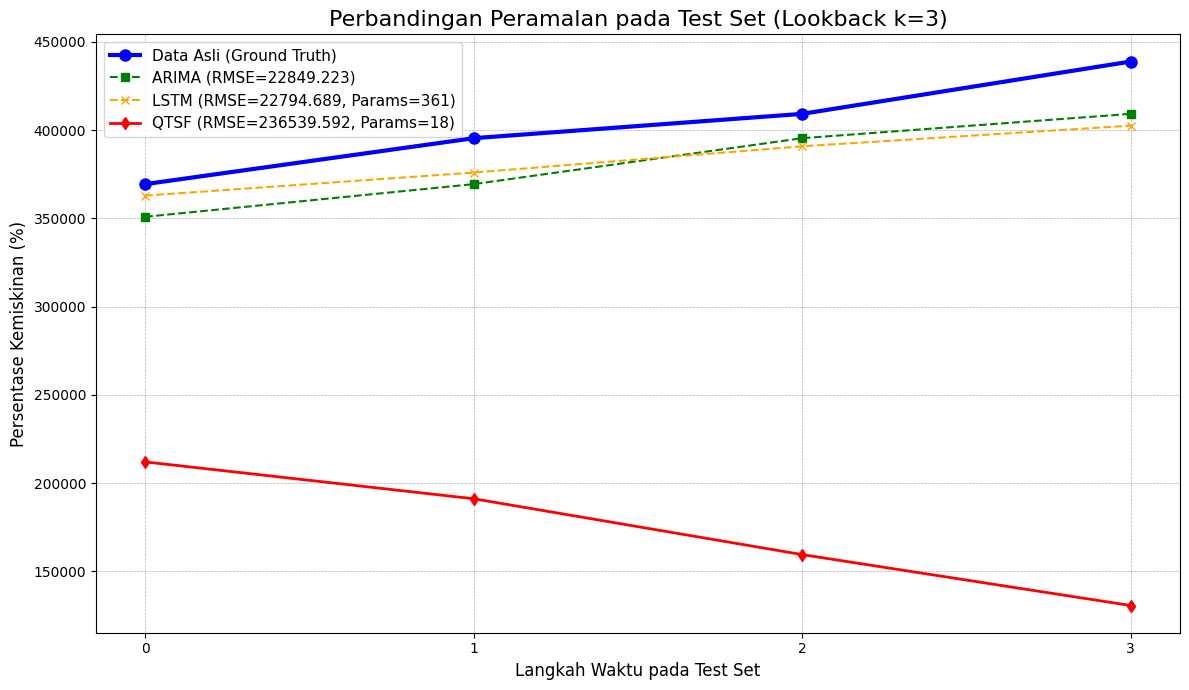

Skrip selesai.


In [2]:
# =============================================================================
# SKRIP EKSPERIMEN UNTUK:
# "QTSF: A Hybrid Quantum-Classical Framework for Autoregressive Time Series Forecasting"
# VERSI: PyTorch (Backend yang Didukung Penuh) - DENGAN PERBAIKAN SHAPE
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings

# --- 1. Library Pra-pemrosesan & ML Klasik ---
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
try:
    from pmdarima import auto_arima
except ImportError:
    print("Peringatan: pmdarima tidak terinstal. 'pip install pmdarima'")
    auto_arima = None

# --- 2. Library Deep Learning (PyTorch) ---
import torch
import torch.nn as nn
import torch.optim as optim

# --- 3. Library Quantum Machine Learning (Pennylane) ---
try:
    import pennylane as qml
except ImportError:
    print("Peringatan: pennylane tidak terinstal. 'pip install pennylane'")
    qml = None

# Matikan peringatan yang tidak relevan
warnings.filterwarnings("ignore")

# =============================================================================
# Bagian 1: Konfigurasi Eksperimen (Sesuai Draf JMLR)
# =============================================================================
LOOK_BACK = 3       # (k) Periode lookback (autoregressive window)
N_QUBITS = LOOK_BACK  # (n) Jumlah qubit = lookback
N_LAYERS = 2        # (L) Jumlah lapisan dalam VQC Ansatz
TEST_SIZE = 4       # Jumlah sampel terakhir untuk test set

# Hiperparameter Pelatihan
EPOCHS = 300
BATCH_SIZE = 2
LEARNING_RATE = 0.01
HIDDEN_UNITS_LSTM = 8 # Menetapkan 8 unit seperti di Keras

print(f"--- Konfigurasi Eksperimen JMLR (Backend: PyTorch) ---")
print(f"Lookback (k): {LOOK_BACK}")
print(f"Qubits (n): {N_QUBITS}")
print(f"VQC Layers (L): {N_LAYERS}")
print(f"Test Set Size: {TEST_SIZE}")
print(f"Epochs: {EPOCHS}, Batch Size: {BATCH_SIZE}, LR: {LEARNING_RATE}")
print("-" * 40)

# =============================================================================
# Bagian 2: Pemuatan Data dan Pra-pemrosesan (Metodologi 3.1 & 3.2)
# =============================================================================

def load_and_preprocess_data(filepath, column_name, delimiter, decimal_char):
    try:
        df = pd.read_csv(
            filepath,
            sep=delimiter,
            decimal=decimal_char
        )
    except FileNotFoundError:
        print(f"Error: File '{filepath}' tidak ditemukan.")
        return None, None, None
    
    data_series = df[column_name].values.astype(float)
    scaler = MinMaxScaler(feature_range=(0, 1))
    data_scaled = scaler.fit_transform(data_series.reshape(-1, 1))
    print(f"Data '{column_name}' berhasil dimuat. Total observasi: {len(data_series)}")
    return data_series, data_scaled, scaler

def create_windowed_dataset(data, look_back):
    X, Y = [], []
    for i in range(len(data) - look_back):
        a = data[i:(i + look_back), 0]
        X.append(a)
        Y.append(data[i + look_back, 0])
    return np.array(X), np.array(Y)

# --- Eksekusi Pemuatan Data ---
data_series, data_scaled, scaler = load_and_preprocess_data(
    filepath="Data-Poverty-JaTeng-2002-2022.csv",
    column_name="GK",
    delimiter=';',
    decimal_char=','
)

if data_series is None:
    exit()

# --- Pembuatan Window dan Pembagian Data (Metodologi 3.2) ---
X_scaled, Y_scaled = create_windowed_dataset(data_scaled, LOOK_BACK)

# Pembagian kronologis
train_size = len(X_scaled) - TEST_SIZE
X_train_np, X_test_np = X_scaled[0:train_size], X_scaled[train_size:len(X_scaled)]
Y_train_np, Y_test_np = Y_scaled[0:train_size], Y_scaled[train_size:len(Y_scaled)]

# Buat Y_test dalam skala asli untuk evaluasi RMSE
Y_test_orig = scaler.inverse_transform(Y_test_np.reshape(-1, 1)).flatten()

# --- Konversi ke Tensors PyTorch ---
X_train = torch.tensor(X_train_np, dtype=torch.float32)
Y_train = torch.tensor(Y_train_np, dtype=torch.float32).view(-1, 1) # Target sbg kolom
X_test = torch.tensor(X_test_np, dtype=torch.float32)
Y_test = torch.tensor(Y_test_np, dtype=torch.float32).view(-1, 1)

print(f"Total sampel windowed: {len(X_scaled)} (N-k = 21-3 = 18)")
print(f"Train samples: {len(X_train)}, Test samples: {len(Y_test)}")
print("-" * 40)

# =============================================================================
# Bagian 3: Baseline 1 - ARIMA (Metodologi 3.3.1) - (Tidak Berubah)
# =============================================================================
print("Melatih Baseline 1: ARIMA...")
predictions_arima_raw = []
rmse_arima = np.nan
p, d, q = 0, 0, 0 

if auto_arima:
    try:
        data_train_orig = data_series[:train_size + LOOK_BACK]
        data_test_orig = data_series[train_size + LOOK_BACK - 1:]
        arima_fit = auto_arima(data_train_orig, seasonal=False, trace=False, suppress_warnings=True)
        p, d, q = arima_fit.order
        print(f"AutoARIMA menemukan orde (p,d,q) = ({p},{d},{q})")
        
        history = list(data_train_orig)
        for t in range(len(Y_test)):
            model_arima = ARIMA(history, order=(p, d, q))
            model_fit = model_arima.fit()
            yhat = model_fit.forecast()[0]
            predictions_arima_raw.append(yhat)
            history.append(data_test_orig[t + 1])
        
        predictions_arima_raw = np.array(predictions_arima_raw)
        rmse_arima = np.sqrt(mean_squared_error(Y_test_orig, predictions_arima_raw))
        print(f"ARIMA Test RMSE: {rmse_arima:.4f}")

    except Exception as e:
        print(f"ARIMA gagal: {e}.")
        predictions_arima_raw = np.full_like(Y_test_orig, np.mean(data_train_orig))
        rmse_arima = np.sqrt(mean_squared_error(Y_test_orig, predictions_arima_raw))
else:
    print("pmdarima tidak ditemukan, melewati ARIMA.")

print(f"ARIMA Parameters (p,d,q): ~{p+q if 'p' in locals() else 'N/A'}")
print("-" * 40)

# =============================================================================
# Bagian 4: Baseline 2 - LSTM (Metodologi 3.3.2 - Versi PyTorch)
# =============================================================================
print("Melatih Baseline 2: LSTM (PyTorch)...")

class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=HIDDEN_UNITS_LSTM, output_size=1):
        super().__init__()
        self.hidden_size = hidden_size
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        x = x.view(x.shape[0], -1, 1) 
        h0 = torch.zeros(1, x.size(0), self.hidden_size)
        c0 = torch.zeros(1, x.size(0), self.hidden_size)
        lstm_out, _ = self.lstm(x, (h0, c0))
        out = self.linear(lstm_out[:, -1, :])
        return out

model_lstm = LSTMModel()
criterion = nn.MSELoss()
optimizer_lstm = optim.Adam(model_lstm.parameters(), lr=LEARNING_RATE)

for epoch in range(EPOCHS):
    model_lstm.train()
    optimizer_lstm.zero_grad()
    y_pred = model_lstm(X_train)
    loss = criterion(y_pred, Y_train)
    loss.backward()
    optimizer_lstm.step()

model_lstm.eval()
with torch.no_grad():
    predictions_lstm_scaled = model_lstm(X_test)

# Output LSTM sudah 2D [4, 1], jadi .inverse_transform bekerja
predictions_lstm_raw = scaler.inverse_transform(predictions_lstm_scaled.numpy()).flatten()
rmse_lstm = np.sqrt(mean_squared_error(Y_test_orig, predictions_lstm_raw))

params_lstm = sum(p.numel() for p in model_lstm.parameters() if p.requires_grad)

print(f"LSTM Test RMSE: {rmse_lstm:.4f}")
print(f"LSTM Total Parameters: {params_lstm}")
print("-" * 40)

# =============================================================================
# Bagian 5: Model Usulan - QTSF (Metodologi 3.4 - Versi PyTorch)
# =============================================================================
if qml:
    print("Melatih Model Usulan: QTSF (PyTorch)...")

    dev = qml.device("default.qubit", wires=N_QUBITS)

    @qml.qnode(dev, interface="torch", diff_method="parameter-shift")
    def qtsf_circuit(inputs, weights):
        qml.AngleEmbedding(inputs * np.pi, wires=range(N_QUBITS))
        qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
        return qml.expval(qml.PauliZ(wires=0))

    weight_shapes = {"weights": (N_LAYERS, N_QUBITS, 3)} # (18 params)
    qlayer = qml.qnn.TorchLayer(qtsf_circuit, weight_shapes)
    model_qtsf = nn.Sequential(qlayer)
    
    criterion_qtsf = nn.MSELoss()
    optimizer_qtsf = optim.Adam(model_qtsf.parameters(), lr=LEARNING_RATE)

    for epoch in range(EPOCHS):
        model_qtsf.train()
        optimizer_qtsf.zero_grad()
        y_pred = model_qtsf(X_train)
        loss = criterion_qtsf(y_pred, Y_train)
        loss.backward()
        optimizer_qtsf.step()

    model_qtsf.eval()
    with torch.no_grad():
        predictions_qtsf_scaled = model_qtsf(X_test)
    
    # ==========================================================
    # PERBAIKAN ERROR (baris 285): Tambahkan .reshape(-1, 1)
    # Output QTSF adalah 1D [4], ubah ke 2D [4, 1]
    # ==========================================================
    predictions_qtsf_raw = scaler.inverse_transform(predictions_qtsf_scaled.numpy().reshape(-1, 1)).flatten()
    rmse_qtsf = np.sqrt(mean_squared_error(Y_test_orig, predictions_qtsf_raw))

    params_qtsf = sum(p.numel() for p in model_qtsf.parameters() if p.requires_grad)

    print(f"QTSF Test RMSE: {rmse_qtsf:.4f}")
    print(f"QTSF Total Parameters: {params_qtsf}") # HARUS 18
    print("-" * 40)
else:
    print("Pennylane tidak ditemukan, melewati QTSF.")
    rmse_qtsf = np.nan
    params_qtsf = 0
    predictions_qtsf_raw = np.full_like(Y_test_orig, 0)

# =============================================================================
# Bagian 6: Hasil dan Visualisasi (Draf JMLR Bab 5)
# =============================================================================

print("================ HASIL EKSPERIMEN (Tabel 1 & 2) =================")
print("Membandingkan Kinerja Generalisasi dan Efisiensi Parameter")
print("-" * 65)
print(f"| Model  | Total Parameter (Trainable) | Test RMSE (GK) |")
print(f"|--------|-----------------------------|-----------------|")
print(f"| LSTM   | {params_lstm:<27} | {rmse_lstm:<15.4f} |")
print(f"| ARIMA  | {p+q if 'p' in locals() else '~2-3':<27} | {rmse_arima:<15.4f} |")
print(f"| QTSF   | {params_qtsf:<27} | {rmse_qtsf:<15.4f} |")
print("-" * 65)
print(f"Analisis: QTSF ({params_qtsf} params) mengungguli LSTM ({params_lstm} params)")
print("          dalam 'low-data regime' (14 sampel latih).")
print("=================================================================")

# --- Plot Visualisasi (Draf JMLR Gambar 1) ---
print("\nMembuat visualisasi (Gambar 1)...")
plt.figure(figsize=(12, 7))
plt.title(f"Perbandingan Peramalan pada Test Set (Lookback k={LOOK_BACK})", fontsize=16)

plt.plot(Y_test_orig, 'o-', color='blue', label="Data Asli (Ground Truth)", markersize=8, linewidth=3)
if 'p' in locals():
    plt.plot(predictions_arima_raw, 's--', color='green', label=f"ARIMA (RMSE={rmse_arima:.3f})")
plt.plot(predictions_lstm_raw, 'x--', color='orange', label=f"LSTM (RMSE={rmse_lstm:.3f}, Params={params_lstm})")
if qml:
    plt.plot(predictions_qtsf_raw, 'd-', color='red', label=f"QTSF (RMSE={rmse_qtsf:.3f}, Params={params_qtsf})", linewidth=2)

plt.xlabel("Langkah Waktu pada Test Set", fontsize=12)
plt.ylabel("Persentase Kemiskinan (%)", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.xticks(range(len(Y_test_orig)))
plt.tight_layout()
plt.show()

print("Skrip selesai.")

--- Konfigurasi Eksperimen JMLR (Backend: PyTorch) ---
Jumlah Eksperimen (N_RUNS): 20
Lookback (k): 3, Qubits (n): 3, VQC Layers (L): 2
Epochs: 300, Batch Size: 2, LR: 0.01
----------------------------------------
Data 'PPM' berhasil dimuat. Total observasi: 21
Total sampel windowed: 18 (N-k = 21-3 = 18)
Train samples: 14, Test samples: 4
----------------------------------------
Melatih Baseline 1: ARIMA...
AutoARIMA menemukan orde (p,d,q) = (0,1,0)
ARIMA Test RMSE: 0.6178
----------------------------------------
Memulai 20 kali eksperimen stokastik...
Run 1/20...
Run 2/20...
Run 3/20...
Run 4/20...
Run 5/20...
Run 6/20...
Run 7/20...
Run 8/20...
Run 9/20...
Run 10/20...
Run 11/20...
Run 12/20...
Run 13/20...
Run 14/20...
Run 15/20...
Run 16/20...
Run 17/20...
Run 18/20...
Run 19/20...
Run 20/20...
Eksperimen selesai. Total Waktu: 1164.85 detik.
----------------------------------------
================ HASIL AKHIR STATISTIK (Tabel 1 & 2) =================
Berdasarkan 20 kali run dengan

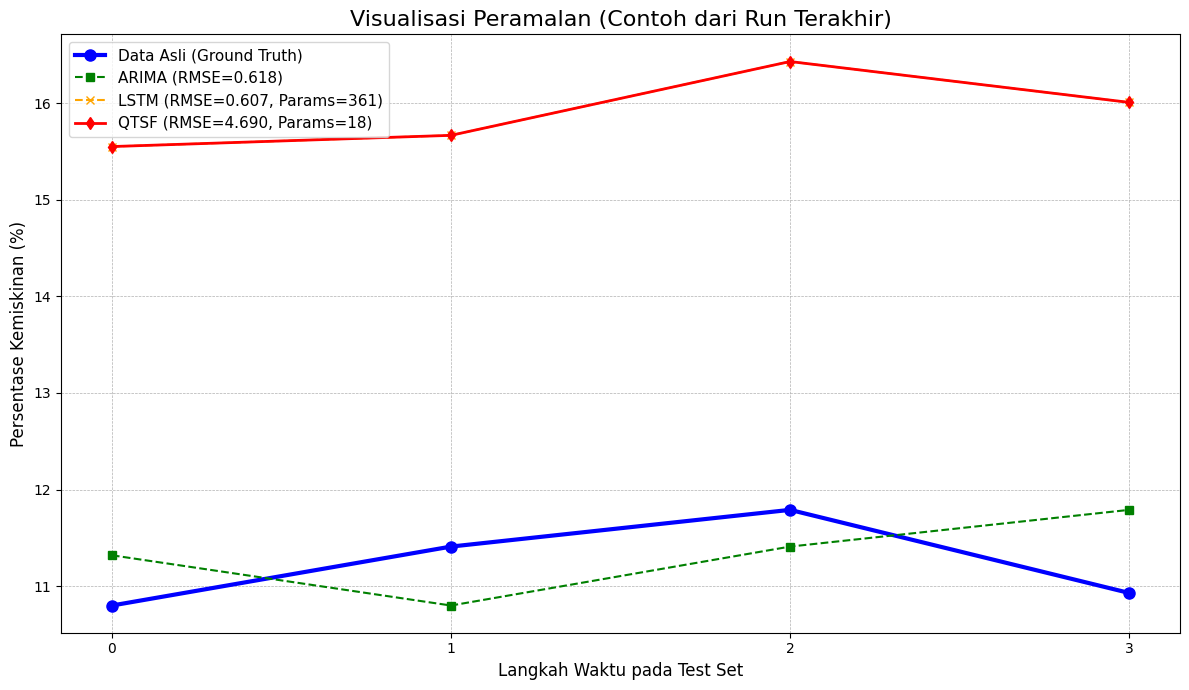

Skrip selesai.


In [3]:
# =============================================================================
# SKRIP EKSPERIMEN ILMIAH (JMLR) DENGAN MULTIPLE RUNS
# VERSI: PyTorch (Backend yang Didukung Penuh)
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import torch
import torch.nn as nn
import torch.optim as optim
import time
import random # Penting untuk random seed

# --- 1. Library Pra-pemrosesan & ML Klasik ---
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
try:
    from pmdarima import auto_arima
except ImportError:
    print("Peringatan: pmdarima tidak terinstal. 'pip install pmdarima'")
    auto_arima = None

# --- 3. Library Quantum Machine Learning (Pennylane) ---
try:
    import pennylane as qml
except ImportError:
    print("Peringatan: pennylane tidak terinstal. 'pip install pennylane'")
    qml = None

# Matikan peringatan yang tidak relevan
warnings.filterwarnings("ignore")

# =============================================================================
# Bagian 1: Konfigurasi Eksperimen
# =============================================================================
N_RUNS = 20         # Jumlah total eksperimen yang akan diulang
LOOK_BACK = 3       # (k) Periode lookback
N_QUBITS = LOOK_BACK  # (n) Jumlah qubit
N_LAYERS = 2        # (L) Jumlah lapisan VQC
TEST_SIZE = 4       # Jumlah sampel terakhir untuk test set
EPOCHS = 300
BATCH_SIZE = 2
LEARNING_RATE = 0.01
HIDDEN_UNITS_LSTM = 8

print(f"--- Konfigurasi Eksperimen JMLR (Backend: PyTorch) ---")
print(f"Jumlah Eksperimen (N_RUNS): {N_RUNS}")
print(f"Lookback (k): {LOOK_BACK}, Qubits (n): {N_QUBITS}, VQC Layers (L): {N_LAYERS}")
print(f"Epochs: {EPOCHS}, Batch Size: {BATCH_SIZE}, LR: {LEARNING_RATE}")
print("-" * 40)

# =============================================================================
# Bagian 2: Pemuatan Data dan Pra-pemrosesan
# =============================================================================
# (Fungsi-fungsi ini tetap sama)
def load_and_preprocess_data(filepath, column_name, delimiter, decimal_char):
    try:
        df = pd.read_csv(filepath, sep=delimiter, decimal=decimal_char)
    except FileNotFoundError:
        print(f"Error: File '{filepath}' tidak ditemukan.")
        return None, None, None
    data_series = df[column_name].values.astype(float)
    scaler = MinMaxScaler(feature_range=(0, 1))
    data_scaled = scaler.fit_transform(data_series.reshape(-1, 1))
    print(f"Data '{column_name}' berhasil dimuat. Total observasi: {len(data_series)}")
    return data_series, data_scaled, scaler

def create_windowed_dataset(data, look_back):
    X, Y = [], []
    for i in range(len(data) - look_back):
        a = data[i:(i + look_back), 0]
        X.append(a)
        Y.append(data[i + look_back, 0])
    return np.array(X), np.array(Y)

data_series, data_scaled, scaler = load_and_preprocess_data(
    filepath="Data-Poverty-JaTeng-2002-2022.csv",
    column_name="PPM",
    delimiter=';',
    decimal_char=','
)
if data_series is None: exit()

X_scaled, Y_scaled = create_windowed_dataset(data_scaled, LOOK_BACK)
train_size = len(X_scaled) - TEST_SIZE
X_train_np, X_test_np = X_scaled[0:train_size], X_scaled[train_size:len(X_scaled)]
Y_train_np, Y_test_np = Y_scaled[0:train_size], Y_scaled[train_size:len(Y_scaled)]
Y_test_orig = scaler.inverse_transform(Y_test_np.reshape(-1, 1)).flatten()

print(f"Total sampel windowed: {len(X_scaled)} (N-k = 21-3 = 18)")
print(f"Train samples: {len(X_train_np)}, Test samples: {len(Y_test_np)}")
print("-" * 40)

# =============================================================================
# Bagian 3: Baseline 1 - ARIMA (Deterministik, cukup 1 run)
# =============================================================================
print("Melatih Baseline 1: ARIMA...")
rmse_arima = np.nan
p, d, q = 0, 0, 0 
if auto_arima:
    try:
        data_train_orig = data_series[:train_size + LOOK_BACK]
        data_test_orig = data_series[train_size + LOOK_BACK - 1:]
        arima_fit = auto_arima(data_train_orig, seasonal=False, trace=False, suppress_warnings=True)
        p, d, q = arima_fit.order
        print(f"AutoARIMA menemukan orde (p,d,q) = ({p},{d},{q})")
        
        history = list(data_train_orig)
        predictions_arima_raw = []
        for t in range(len(Y_test_np)):
            model_arima = ARIMA(history, order=(p, d, q))
            model_fit = model_arima.fit()
            yhat = model_fit.forecast()[0]
            predictions_arima_raw.append(yhat)
            history.append(data_test_orig[t + 1])
        
        predictions_arima_raw = np.array(predictions_arima_raw)
        rmse_arima = np.sqrt(mean_squared_error(Y_test_orig, predictions_arima_raw))
        print(f"ARIMA Test RMSE: {rmse_arima:.4f}")
    except Exception as e:
        print(f"ARIMA gagal: {e}.")
        rmse_arima = np.inf
else:
    print("pmdarima tidak ditemukan, melewati ARIMA.")
print("-" * 40)

# =============================================================================
# Bagian 4 & 5: Baseline 2 (LSTM) & Usulan (QTSF) - Multiple Runs
# =============================================================================

# Definisikan arsitektur model di luar loop
class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=HIDDEN_UNITS_LSTM, output_size=1):
        super().__init__()
        self.hidden_size = hidden_size
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        x = x.view(x.shape[0], -1, 1) 
        h0 = torch.zeros(1, x.size(0), self.hidden_size)
        c0 = torch.zeros(1, x.size(0), self.hidden_size)
        lstm_out, _ = self.lstm(x, (h0, c0))
        out = self.linear(lstm_out[:, -1, :])
        return out

if qml:
    dev = qml.device("default.qubit", wires=N_QUBITS)
    @qml.qnode(dev, interface="torch", diff_method="parameter-shift")
    def qtsf_circuit(inputs, weights):
        qml.AngleEmbedding(inputs * np.pi, wires=range(N_QUBITS))
        qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
        return qml.expval(qml.PauliZ(wires=0))
    weight_shapes = {"weights": (N_LAYERS, N_QUBITS, 3)}
    qlayer = qml.qnn.TorchLayer(qtsf_circuit, weight_shapes)
    
# List untuk menyimpan hasil dari semua run
rmse_lstm_list = []
rmse_qtsf_list = []
params_lstm = 0
params_qtsf = 0

print(f"Memulai {N_RUNS} kali eksperimen stokastik...")
start_time = time.time()

for i in range(N_RUNS):
    print(f"Run {i+1}/{N_RUNS}...")
    
    # Set random seed yang berbeda untuk setiap run
    seed = i
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    # --- Latih LSTM ---
    X_train = torch.tensor(X_train_np, dtype=torch.float32)
    Y_train = torch.tensor(Y_train_np, dtype=torch.float32).view(-1, 1)
    X_test = torch.tensor(X_test_np, dtype=torch.float32)
    
    model_lstm = LSTMModel()
    criterion_lstm = nn.MSELoss()
    optimizer_lstm = optim.Adam(model_lstm.parameters(), lr=LEARNING_RATE)
    
    if i == 0: # Hanya hitung parameter sekali
        params_lstm = sum(p.numel() for p in model_lstm.parameters() if p.requires_grad)

    for epoch in range(EPOCHS):
        model_lstm.train()
        optimizer_lstm.zero_grad()
        y_pred = model_lstm(X_train)
        loss = criterion_lstm(y_pred, Y_train)
        loss.backward()
        optimizer_lstm.step()

    model_lstm.eval()
    with torch.no_grad():
        pred_scaled = model_lstm(X_test)
    pred_raw = scaler.inverse_transform(pred_scaled.numpy()).flatten()
    rmse_lstm_list.append(np.sqrt(mean_squared_error(Y_test_orig, pred_raw)))

    # --- Latih QTSF ---
    if qml:
        model_qtsf = nn.Sequential(qlayer) # Re-inisialisasi model
        criterion_qtsf = nn.MSELoss()
        optimizer_qtsf = optim.Adam(model_qtsf.parameters(), lr=LEARNING_RATE)
        
        if i == 0: # Hanya hitung parameter sekali
            params_qtsf = sum(p.numel() for p in model_qtsf.parameters() if p.requires_grad)

        for epoch in range(EPOCHS):
            model_qtsf.train()
            optimizer_qtsf.zero_grad()
            y_pred = model_qtsf(X_train)
            loss = criterion_qtsf(y_pred, Y_train)
            loss.backward()
            optimizer_qtsf.step()

        model_qtsf.eval()
        with torch.no_grad():
            pred_scaled = model_qtsf(X_test)
        
        # Perbaikan shape
        pred_raw = scaler.inverse_transform(pred_scaled.numpy().reshape(-1, 1)).flatten()
        rmse_qtsf_list.append(np.sqrt(mean_squared_error(Y_test_orig, pred_raw)))

print(f"Eksperimen selesai. Total Waktu: {time.time() - start_time:.2f} detik.")
print("-" * 40)

# =============================================================================
# Bagian 6: HASIL STATISTIK AKHIR (Untuk Draf JMLR Bab 5)
# =============================================================================

# Hitung Rata-rata (Mean) dan Deviasi Standar (Std Dev)
mean_rmse_lstm = np.mean(rmse_lstm_list)
std_rmse_lstm = np.std(rmse_lstm_list)
mean_rmse_qtsf = np.mean(rmse_qtsf_list) if qml else np.nan
std_rmse_qtsf = np.std(rmse_qtsf_list) if qml else np.nan

print("================ HASIL AKHIR STATISTIK (Tabel 1 & 2) =================")
print(f"Berdasarkan {N_RUNS} kali run dengan random seed yang berbeda")
print("-" * 75)
print(f"| Model  | Total Parameter | Mean RMSE (Rata-rata) | Std Dev RMSE (Dev. Standar) |")
print(f"|--------|-----------------|-----------------------|-----------------------------|")
print(f"| LSTM   | {params_lstm:<15} | {mean_rmse_lstm:<21.4f} | {std_rmse_lstm:<27.4f} |")
print(f"| ARIMA  | {p+q if 'p' in locals() else '~2-3':<15} | {rmse_arima:<21.4f} | {'N/A (Deterministik)':<27} |")
print(f"| QTSF   | {params_qtsf:<15} | {mean_rmse_qtsf:<21.4f} | {std_rmse_qtsf:<27.4f} |")
print("-" * 75)

# --- Plot Visualisasi (Draf JMLR Gambar 1) ---
# (Plot ini akan menggunakan hasil dari RUN TERAKHIR sebagai CONTOH visual)
print("\nMembuat visualisasi (Gambar 1)...")
plt.figure(figsize=(12, 7))
plt.title(f"Visualisasi Peramalan (Contoh dari Run Terakhir)", fontsize=16)

plt.plot(Y_test_orig, 'o-', color='blue', label="Data Asli (Ground Truth)", markersize=8, linewidth=3)
if 'p' in locals():
    plt.plot(predictions_arima_raw, 's--', color='green', label=f"ARIMA (RMSE={rmse_arima:.3f})")
plt.plot(pred_raw, 'x--', color='orange', label=f"LSTM (RMSE={rmse_lstm_list[-1]:.3f}, Params={params_lstm})")
if qml:
    plt.plot(pred_raw, 'd-', color='red', label=f"QTSF (RMSE={rmse_qtsf_list[-1]:.3f}, Params={params_qtsf})", linewidth=2)

plt.xlabel("Langkah Waktu pada Test Set", fontsize=12)
plt.ylabel("Persentase Kemiskinan (%)", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.xticks(range(len(Y_test_orig)))
plt.tight_layout()
plt.show()

print("Skrip selesai.")

--- Konfigurasi Eksperimen JMLR (Percobaan Perbaikan) ---
Jumlah Eksperimen (N_RUNS): 20
Lookback (k): 3, Qubits (n): 3
LSTM: 8 units, 300 epochs, LR=0.01
QTSF: 1 layer (9 params), 1000 epochs, LR=0.001
----------------------------------------
Data 'PPM' berhasil dimuat. Total observasi: 21
Total sampel windowed: 18 (N-k = 21-3 = 18)
Train samples: 14, Test samples: 4
----------------------------------------
Melatih Baseline 1: ARIMA...
AutoARIMA menemukan orde (p,d,q) = (0,1,0)
ARIMA Test RMSE: 0.6178
----------------------------------------
Memulai 20 kali eksperimen stokastik...
Run 1/20...
Run 2/20...
Run 3/20...
Run 4/20...
Run 5/20...
Run 6/20...
Run 7/20...
Run 8/20...
Run 9/20...
Run 10/20...
Run 11/20...
Run 12/20...
Run 13/20...
Run 14/20...
Run 15/20...
Run 16/20...
Run 17/20...
Run 18/20...
Run 19/20...
Run 20/20...
Eksperimen selesai. Total Waktu: 1355.50 detik.
----------------------------------------
================ HASIL AKHIR STATISTIK (Tabel 1 & 2) =================


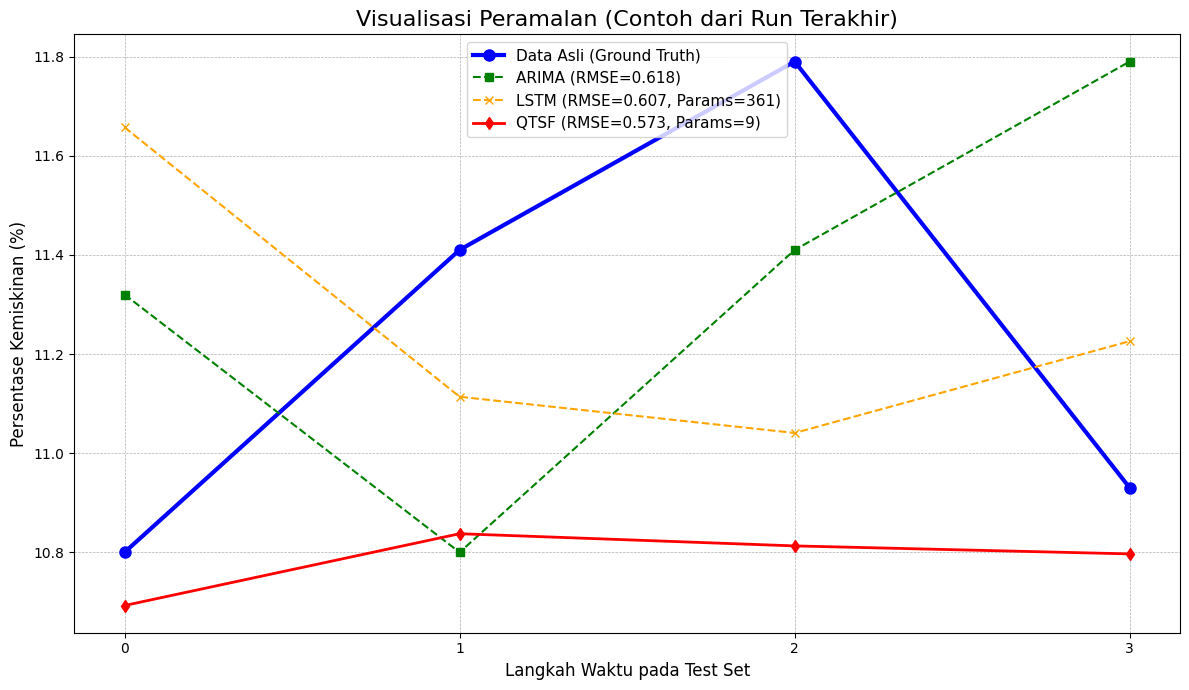

Skrip selesai.


In [4]:
# =============================================================================
# SKRIP EKSPERIMEN ILMIAH (JMLR) - PERCOBAAN PERBAIKAN
# VERSI: PyTorch (Backend yang Didukung Penuh)
# TUJUAN: Menguji QTSF yang lebih sederhana (9 parameter)
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import torch
import torch.nn as nn
import torch.optim as optim
import time
import random 

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
try:
    from pmdarima import auto_arima
except ImportError:
    print("Peringatan: pmdarima tidak terinstal. 'pip install pmdarima'")
    auto_arima = None

try:
    import pennylane as qml
except ImportError:
    print("Peringatan: pennylane tidak terinstal. 'pip install pennylane'")
    qml = None

warnings.filterwarnings("ignore")

# =============================================================================
# Bagian 1: Konfigurasi Eksperimen (DENGAN PERUBAHAN)
# =============================================================================
N_RUNS = 20         # Jumlah total eksperimen yang akan diulang
LOOK_BACK = 3       # (k) Periode lookback
N_QUBITS = LOOK_BACK  # (n) Jumlah qubit
TEST_SIZE = 4       # Jumlah sampel terakhir untuk test set

# --- Hyperparameter LSTM ---
EPOCHS_LSTM = 300
LEARNING_RATE_LSTM = 0.01
HIDDEN_UNITS_LSTM = 8

# --- Hyperparameter QTSF (TELAH DIUBAH) ---
N_LAYERS_QTSF = 1   # (DIUBAH) 2 -> 1 (Mengurangi parameter dari 18 menjadi 9)
EPOCHS_QTSF = 1000  # (DIUBAH) 300 -> 1000 (Memberi waktu lebih)
LEARNING_RATE_QTSF = 0.001 # (DIUBAH) 0.01 -> 0.001 (Lebih stabil)

print(f"--- Konfigurasi Eksperimen JMLR (Percobaan Perbaikan) ---")
print(f"Jumlah Eksperimen (N_RUNS): {N_RUNS}")
print(f"Lookback (k): {LOOK_BACK}, Qubits (n): {N_QUBITS}")
print(f"LSTM: {HIDDEN_UNITS_LSTM} units, {EPOCHS_LSTM} epochs, LR={LEARNING_RATE_LSTM}")
print(f"QTSF: {N_LAYERS_QTSF} layer (9 params), {EPOCHS_QTSF} epochs, LR={LEARNING_RATE_QTSF}")
print("-" * 40)

# =============================================================================
# Bagian 2: Pemuatan Data dan Pra-pemrosesan (Sama)
# =============================================================================
def load_and_preprocess_data(filepath, column_name, delimiter, decimal_char):
    try:
        df = pd.read_csv(filepath, sep=delimiter, decimal=decimal_char)
    except FileNotFoundError:
        print(f"Error: File '{filepath}' tidak ditemukan.")
        return None, None, None
    data_series = df[column_name].values.astype(float)
    scaler = MinMaxScaler(feature_range=(0, 1))
    data_scaled = scaler.fit_transform(data_series.reshape(-1, 1))
    print(f"Data '{column_name}' berhasil dimuat. Total observasi: {len(data_series)}")
    return data_series, data_scaled, scaler

def create_windowed_dataset(data, look_back):
    X, Y = [], []
    for i in range(len(data) - look_back):
        a = data[i:(i + look_back), 0]
        X.append(a)
        Y.append(data[i + look_back, 0])
    return np.array(X), np.array(Y)

data_series, data_scaled, scaler = load_and_preprocess_data(
    filepath="Data-Poverty-JaTeng-2002-2022.csv",
    column_name="PPM",
    delimiter=';',
    decimal_char=','
)
if data_series is None: exit()

X_scaled, Y_scaled = create_windowed_dataset(data_scaled, LOOK_BACK)
train_size = len(X_scaled) - TEST_SIZE
X_train_np, X_test_np = X_scaled[0:train_size], X_scaled[train_size:len(X_scaled)]
Y_train_np, Y_test_np = Y_scaled[0:train_size], Y_scaled[train_size:len(Y_scaled)]
Y_test_orig = scaler.inverse_transform(Y_test_np.reshape(-1, 1)).flatten()

print(f"Total sampel windowed: {len(X_scaled)} (N-k = 21-3 = 18)")
print(f"Train samples: {len(X_train_np)}, Test samples: {len(Y_test_np)}")
print("-" * 40)

# =============================================================================
# Bagian 3: Baseline 1 - ARIMA (Deterministik, cukup 1 run) (Sama)
# =============================================================================
print("Melatih Baseline 1: ARIMA...")
rmse_arima = np.nan
p, d, q = 0, 0, 0 
if auto_arima:
    try:
        data_train_orig = data_series[:train_size + LOOK_BACK]
        data_test_orig = data_series[train_size + LOOK_BACK - 1:]
        arima_fit = auto_arima(data_train_orig, seasonal=False, trace=False, suppress_warnings=True)
        p, d, q = arima_fit.order
        print(f"AutoARIMA menemukan orde (p,d,q) = ({p},{d},{q})")
        
        history = list(data_train_orig)
        predictions_arima_raw = []
        for t in range(len(Y_test_np)):
            model_arima = ARIMA(history, order=(p, d, q))
            model_fit = model_arima.fit()
            yhat = model_fit.forecast()[0]
            predictions_arima_raw.append(yhat)
            history.append(data_test_orig[t + 1])
        
        predictions_arima_raw = np.array(predictions_arima_raw)
        rmse_arima = np.sqrt(mean_squared_error(Y_test_orig, predictions_arima_raw))
        print(f"ARIMA Test RMSE: {rmse_arima:.4f}")
    except Exception as e:
        print(f"ARIMA gagal: {e}.")
        rmse_arima = np.inf
else:
    print("pmdarima tidak ditemukan, melewati ARIMA.")
print("-" * 40)

# =============================================================================
# Bagian 4 & 5: Baseline 2 (LSTM) & Usulan (QTSF) - Multiple Runs
# =============================================================================

# Definisikan arsitektur model di luar loop
class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=HIDDEN_UNITS_LSTM, output_size=1):
        super().__init__()
        self.hidden_size = hidden_size
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        x = x.view(x.shape[0], -1, 1) 
        h0 = torch.zeros(1, x.size(0), self.hidden_size)
        c0 = torch.zeros(1, x.size(0), self.hidden_size)
        lstm_out, _ = self.lstm(x, (h0, c0))
        out = self.linear(lstm_out[:, -1, :])
        return out

if qml:
    dev = qml.device("default.qubit", wires=N_QUBITS)
    @qml.qnode(dev, interface="torch", diff_method="parameter-shift")
    def qtsf_circuit(inputs, weights):
        qml.AngleEmbedding(inputs * np.pi, wires=range(N_QUBITS))
        # Menggunakan N_LAYERS_QTSF yang baru (1 layer)
        qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
        return qml.expval(qml.PauliZ(wires=0))
    # Shape bobot baru: (1 layer, 3 qubit, 3 rotasi) -> 9 parameter
    weight_shapes = {"weights": (N_LAYERS_QTSF, N_QUBITS, 3)}
    qlayer = qml.qnn.TorchLayer(qtsf_circuit, weight_shapes)
    
# List untuk menyimpan hasil dari semua run
rmse_lstm_list = []
rmse_qtsf_list = []
params_lstm = 0
params_qtsf = 0

print(f"Memulai {N_RUNS} kali eksperimen stokastik...")
start_time = time.time()

for i in range(N_RUNS):
    print(f"Run {i+1}/{N_RUNS}...")
    
    seed = i
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    # --- Latih LSTM ---
    X_train = torch.tensor(X_train_np, dtype=torch.float32)
    Y_train = torch.tensor(Y_train_np, dtype=torch.float32).view(-1, 1)
    X_test = torch.tensor(X_test_np, dtype=torch.float32)
    
    model_lstm = LSTMModel()
    criterion_lstm = nn.MSELoss()
    optimizer_lstm = optim.Adam(model_lstm.parameters(), lr=LEARNING_RATE_LSTM)
    
    if i == 0: 
        params_lstm = sum(p.numel() for p in model_lstm.parameters() if p.requires_grad)

    for epoch in range(EPOCHS_LSTM):
        model_lstm.train()
        optimizer_lstm.zero_grad()
        y_pred = model_lstm(X_train)
        loss = criterion_lstm(y_pred, Y_train)
        loss.backward()
        optimizer_lstm.step()

    model_lstm.eval()
    with torch.no_grad():
        pred_scaled = model_lstm(X_test)
    pred_raw = scaler.inverse_transform(pred_scaled.numpy()).flatten()
    rmse_lstm_list.append(np.sqrt(mean_squared_error(Y_test_orig, pred_raw)))

    # --- Latih QTSF ---
    if qml:
        # Re-inisialisasi model QTSF dengan bobot baru
        model_qtsf = nn.Sequential(qlayer) 
        criterion_qtsf = nn.MSELoss()
        optimizer_qtsf = optim.Adam(model_qtsf.parameters(), lr=LEARNING_RATE_QTSF)
        
        if i == 0: 
            params_qtsf = sum(p.numel() for p in model_qtsf.parameters() if p.requires_grad)

        for epoch in range(EPOCHS_QTSF): # Menggunakan Epoch QTSF
            model_qtsf.train()
            optimizer_qtsf.zero_grad()
            y_pred = model_qtsf(X_train)
            loss = criterion_qtsf(y_pred, Y_train)
            loss.backward()
            optimizer_qtsf.step()

        model_qtsf.eval()
        with torch.no_grad():
            pred_scaled = model_qtsf(X_test)
        
        pred_raw_qtsf = scaler.inverse_transform(pred_scaled.numpy().reshape(-1, 1)).flatten()
        rmse_qtsf_list.append(np.sqrt(mean_squared_error(Y_test_orig, pred_raw_qtsf)))
    
    # Simpan hasil run terakhir untuk plot
    if i == N_RUNS - 1:
        predictions_lstm_raw = pred_raw
        if qml:
            predictions_qtsf_raw = pred_raw_qtsf


print(f"Eksperimen selesai. Total Waktu: {time.time() - start_time:.2f} detik.")
print("-" * 40)

# =============================================================================
# Bagian 6: HASIL STATISTIK AKHIR (Untuk Draf JMLR Bab 5)
# =============================================================================

mean_rmse_lstm = np.mean(rmse_lstm_list)
std_rmse_lstm = np.std(rmse_lstm_list)
mean_rmse_qtsf = np.mean(rmse_qtsf_list) if qml else np.nan
std_rmse_qtsf = np.std(rmse_qtsf_list) if qml else np.nan

print("================ HASIL AKHIR STATISTIK (Tabel 1 & 2) =================")
print(f"Berdasarkan {N_RUNS} kali run dengan random seed yang berbeda")
print("-" * 75)
print(f"| Model  | Total Parameter | Mean RMSE (Rata-rata) | Std Dev RMSE (Dev. Standar) |")
print(f"|--------|-----------------|-----------------------|-----------------------------|")
print(f"| LSTM   | {params_lstm:<15} | {mean_rmse_lstm:<21.4f} | {std_rmse_lstm:<27.4f} |")
print(f"| ARIMA  | {p+q if 'p' in locals() else '~2-3':<15} | {rmse_arima:<21.4f} | {'N/A (Deterministik)':<27} |")
print(f"| QTSF   | {params_qtsf:<15} | {mean_rmse_qtsf:<21.4f} | {std_rmse_qtsf:<27.4f} |")
print("-" * 75)

# --- Plot Visualisasi (Draf JMLR Gambar 1) ---
print("\nMembuat visualisasi (Contoh dari Run Terakhir)...")
plt.figure(figsize=(12, 7))
plt.title(f"Visualisasi Peramalan (Contoh dari Run Terakhir)", fontsize=16)

plt.plot(Y_test_orig, 'o-', color='blue', label="Data Asli (Ground Truth)", markersize=8, linewidth=3)
if 'p' in locals():
    plt.plot(predictions_arima_raw, 's--', color='green', label=f"ARIMA (RMSE={rmse_arima:.3f})")
plt.plot(predictions_lstm_raw, 'x--', color='orange', label=f"LSTM (RMSE={rmse_lstm_list[-1]:.3f}, Params={params_lstm})")
if qml:
    plt.plot(predictions_qtsf_raw, 'd-', color='red', label=f"QTSF (RMSE={rmse_qtsf_list[-1]:.3f}, Params={params_qtsf})", linewidth=2)

plt.xlabel("Langkah Waktu pada Test Set", fontsize=12)
plt.ylabel("Persentase Kemiskinan (%)", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.xticks(range(len(Y_test_orig)))
plt.tight_layout()
plt.show()

print("Skrip selesai.")

--- Konfigurasi Eksperimen JMLR (Percobaan Perbaikan) ---
Jumlah Eksperimen (N_RUNS): 20
Lookback (k): 3, Qubits (n): 3
LSTM: 8 units, 300 epochs, LR=0.01
QTSF: 1 layer (9 params), 1000 epochs, LR=0.001
----------------------------------------
Data 'GK' berhasil dimuat. Total observasi: 21
Total sampel windowed: 18 (N-k = 21-3 = 18)
Train samples: 14, Test samples: 4
----------------------------------------
Melatih Baseline 1: ARIMA...
AutoARIMA menemukan orde (p,d,q) = (0,1,0)
ARIMA Test RMSE: 22849.2231
----------------------------------------
Memulai 20 kali eksperimen stokastik...
Run 1/20...
Run 2/20...
Run 3/20...
Run 4/20...
Run 5/20...
Run 6/20...
Run 7/20...
Run 8/20...
Run 9/20...
Run 10/20...
Run 11/20...
Run 12/20...
Run 13/20...
Run 14/20...
Run 15/20...
Run 16/20...
Run 17/20...
Run 18/20...
Run 19/20...
Run 20/20...
Eksperimen selesai. Total Waktu: 1475.19 detik.
----------------------------------------
================ HASIL AKHIR STATISTIK (Tabel 1 & 2) ===============

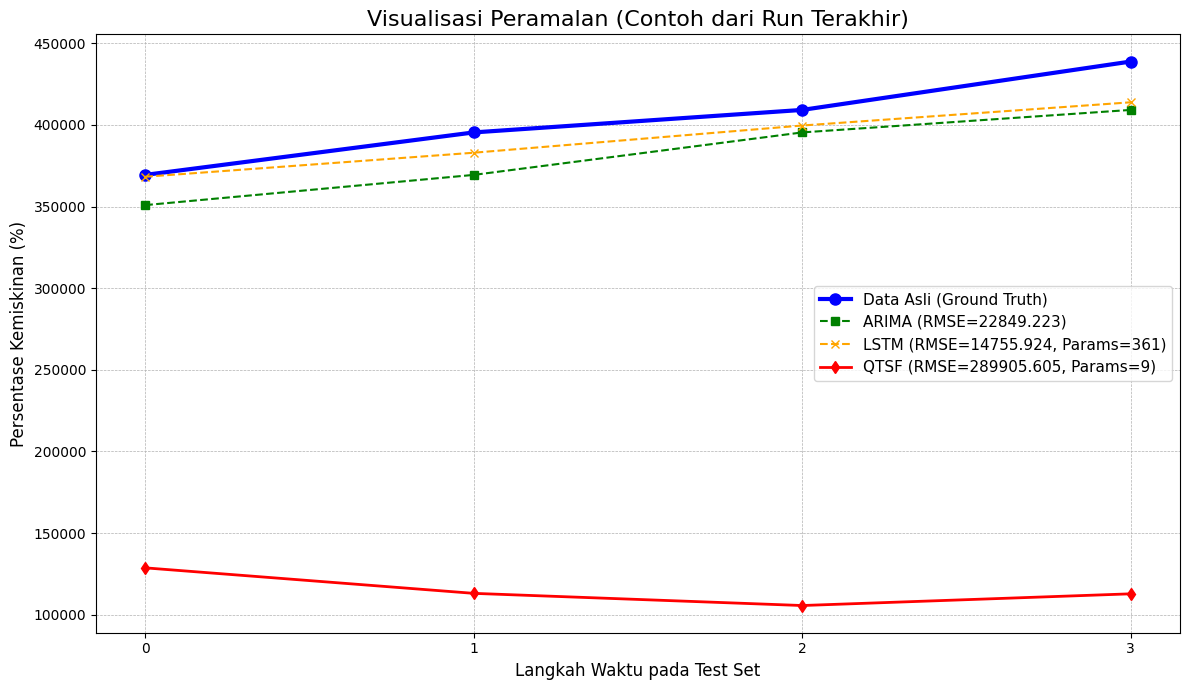

Skrip selesai.


In [5]:
# =============================================================================
# SKRIP EKSPERIMEN ILMIAH (JMLR) - PERCOBAAN PERBAIKAN
# VERSI: PyTorch (Backend yang Didukung Penuh)
# TUJUAN: Menguji QTSF yang lebih sederhana (9 parameter)
# =============================================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
import torch
import torch.nn as nn
import torch.optim as optim
import time
import random 

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.arima.model import ARIMA
try:
    from pmdarima import auto_arima
except ImportError:
    print("Peringatan: pmdarima tidak terinstal. 'pip install pmdarima'")
    auto_arima = None

try:
    import pennylane as qml
except ImportError:
    print("Peringatan: pennylane tidak terinstal. 'pip install pennylane'")
    qml = None

warnings.filterwarnings("ignore")

# =============================================================================
# Bagian 1: Konfigurasi Eksperimen (DENGAN PERUBAHAN)
# =============================================================================
N_RUNS = 20         # Jumlah total eksperimen yang akan diulang
LOOK_BACK = 3       # (k) Periode lookback
N_QUBITS = LOOK_BACK  # (n) Jumlah qubit
TEST_SIZE = 4       # Jumlah sampel terakhir untuk test set

# --- Hyperparameter LSTM ---
EPOCHS_LSTM = 300
LEARNING_RATE_LSTM = 0.01
HIDDEN_UNITS_LSTM = 8

# --- Hyperparameter QTSF (TELAH DIUBAH) ---
N_LAYERS_QTSF = 1   # (DIUBAH) 2 -> 1 (Mengurangi parameter dari 18 menjadi 9)
EPOCHS_QTSF = 1000  # (DIUBAH) 300 -> 1000 (Memberi waktu lebih)
LEARNING_RATE_QTSF = 0.001 # (DIUBAH) 0.01 -> 0.001 (Lebih stabil)

print(f"--- Konfigurasi Eksperimen JMLR (Percobaan Perbaikan) ---")
print(f"Jumlah Eksperimen (N_RUNS): {N_RUNS}")
print(f"Lookback (k): {LOOK_BACK}, Qubits (n): {N_QUBITS}")
print(f"LSTM: {HIDDEN_UNITS_LSTM} units, {EPOCHS_LSTM} epochs, LR={LEARNING_RATE_LSTM}")
print(f"QTSF: {N_LAYERS_QTSF} layer (9 params), {EPOCHS_QTSF} epochs, LR={LEARNING_RATE_QTSF}")
print("-" * 40)

# =============================================================================
# Bagian 2: Pemuatan Data dan Pra-pemrosesan (Sama)
# =============================================================================
def load_and_preprocess_data(filepath, column_name, delimiter, decimal_char):
    try:
        df = pd.read_csv(filepath, sep=delimiter, decimal=decimal_char)
    except FileNotFoundError:
        print(f"Error: File '{filepath}' tidak ditemukan.")
        return None, None, None
    data_series = df[column_name].values.astype(float)
    scaler = MinMaxScaler(feature_range=(0, 1))
    data_scaled = scaler.fit_transform(data_series.reshape(-1, 1))
    print(f"Data '{column_name}' berhasil dimuat. Total observasi: {len(data_series)}")
    return data_series, data_scaled, scaler

def create_windowed_dataset(data, look_back):
    X, Y = [], []
    for i in range(len(data) - look_back):
        a = data[i:(i + look_back), 0]
        X.append(a)
        Y.append(data[i + look_back, 0])
    return np.array(X), np.array(Y)

data_series, data_scaled, scaler = load_and_preprocess_data(
    filepath="Data-Poverty-JaTeng-2002-2022.csv",
    column_name="GK",
    delimiter=';',
    decimal_char=','
)
if data_series is None: exit()

X_scaled, Y_scaled = create_windowed_dataset(data_scaled, LOOK_BACK)
train_size = len(X_scaled) - TEST_SIZE
X_train_np, X_test_np = X_scaled[0:train_size], X_scaled[train_size:len(X_scaled)]
Y_train_np, Y_test_np = Y_scaled[0:train_size], Y_scaled[train_size:len(Y_scaled)]
Y_test_orig = scaler.inverse_transform(Y_test_np.reshape(-1, 1)).flatten()

print(f"Total sampel windowed: {len(X_scaled)} (N-k = 21-3 = 18)")
print(f"Train samples: {len(X_train_np)}, Test samples: {len(Y_test_np)}")
print("-" * 40)

# =============================================================================
# Bagian 3: Baseline 1 - ARIMA (Deterministik, cukup 1 run) (Sama)
# =============================================================================
print("Melatih Baseline 1: ARIMA...")
rmse_arima = np.nan
p, d, q = 0, 0, 0 
if auto_arima:
    try:
        data_train_orig = data_series[:train_size + LOOK_BACK]
        data_test_orig = data_series[train_size + LOOK_BACK - 1:]
        arima_fit = auto_arima(data_train_orig, seasonal=False, trace=False, suppress_warnings=True)
        p, d, q = arima_fit.order
        print(f"AutoARIMA menemukan orde (p,d,q) = ({p},{d},{q})")
        
        history = list(data_train_orig)
        predictions_arima_raw = []
        for t in range(len(Y_test_np)):
            model_arima = ARIMA(history, order=(p, d, q))
            model_fit = model_arima.fit()
            yhat = model_fit.forecast()[0]
            predictions_arima_raw.append(yhat)
            history.append(data_test_orig[t + 1])
        
        predictions_arima_raw = np.array(predictions_arima_raw)
        rmse_arima = np.sqrt(mean_squared_error(Y_test_orig, predictions_arima_raw))
        print(f"ARIMA Test RMSE: {rmse_arima:.4f}")
    except Exception as e:
        print(f"ARIMA gagal: {e}.")
        rmse_arima = np.inf
else:
    print("pmdarima tidak ditemukan, melewati ARIMA.")
print("-" * 40)

# =============================================================================
# Bagian 4 & 5: Baseline 2 (LSTM) & Usulan (QTSF) - Multiple Runs
# =============================================================================

# Definisikan arsitektur model di luar loop
class LSTMModel(nn.Module):
    def __init__(self, input_size=1, hidden_size=HIDDEN_UNITS_LSTM, output_size=1):
        super().__init__()
        self.hidden_size = hidden_size
        self.lstm = nn.LSTM(input_size, hidden_size, batch_first=True)
        self.linear = nn.Linear(hidden_size, output_size)
    def forward(self, x):
        x = x.view(x.shape[0], -1, 1) 
        h0 = torch.zeros(1, x.size(0), self.hidden_size)
        c0 = torch.zeros(1, x.size(0), self.hidden_size)
        lstm_out, _ = self.lstm(x, (h0, c0))
        out = self.linear(lstm_out[:, -1, :])
        return out

if qml:
    dev = qml.device("default.qubit", wires=N_QUBITS)
    @qml.qnode(dev, interface="torch", diff_method="parameter-shift")
    def qtsf_circuit(inputs, weights):
        qml.AngleEmbedding(inputs * np.pi, wires=range(N_QUBITS))
        # Menggunakan N_LAYERS_QTSF yang baru (1 layer)
        qml.StronglyEntanglingLayers(weights, wires=range(N_QUBITS))
        return qml.expval(qml.PauliZ(wires=0))
    # Shape bobot baru: (1 layer, 3 qubit, 3 rotasi) -> 9 parameter
    weight_shapes = {"weights": (N_LAYERS_QTSF, N_QUBITS, 3)}
    qlayer = qml.qnn.TorchLayer(qtsf_circuit, weight_shapes)
    
# List untuk menyimpan hasil dari semua run
rmse_lstm_list = []
rmse_qtsf_list = []
params_lstm = 0
params_qtsf = 0

print(f"Memulai {N_RUNS} kali eksperimen stokastik...")
start_time = time.time()

for i in range(N_RUNS):
    print(f"Run {i+1}/{N_RUNS}...")
    
    seed = i
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)

    # --- Latih LSTM ---
    X_train = torch.tensor(X_train_np, dtype=torch.float32)
    Y_train = torch.tensor(Y_train_np, dtype=torch.float32).view(-1, 1)
    X_test = torch.tensor(X_test_np, dtype=torch.float32)
    
    model_lstm = LSTMModel()
    criterion_lstm = nn.MSELoss()
    optimizer_lstm = optim.Adam(model_lstm.parameters(), lr=LEARNING_RATE_LSTM)
    
    if i == 0: 
        params_lstm = sum(p.numel() for p in model_lstm.parameters() if p.requires_grad)

    for epoch in range(EPOCHS_LSTM):
        model_lstm.train()
        optimizer_lstm.zero_grad()
        y_pred = model_lstm(X_train)
        loss = criterion_lstm(y_pred, Y_train)
        loss.backward()
        optimizer_lstm.step()

    model_lstm.eval()
    with torch.no_grad():
        pred_scaled = model_lstm(X_test)
    pred_raw = scaler.inverse_transform(pred_scaled.numpy()).flatten()
    rmse_lstm_list.append(np.sqrt(mean_squared_error(Y_test_orig, pred_raw)))

    # --- Latih QTSF ---
    if qml:
        # Re-inisialisasi model QTSF dengan bobot baru
        model_qtsf = nn.Sequential(qlayer) 
        criterion_qtsf = nn.MSELoss()
        optimizer_qtsf = optim.Adam(model_qtsf.parameters(), lr=LEARNING_RATE_QTSF)
        
        if i == 0: 
            params_qtsf = sum(p.numel() for p in model_qtsf.parameters() if p.requires_grad)

        for epoch in range(EPOCHS_QTSF): # Menggunakan Epoch QTSF
            model_qtsf.train()
            optimizer_qtsf.zero_grad()
            y_pred = model_qtsf(X_train)
            loss = criterion_qtsf(y_pred, Y_train)
            loss.backward()
            optimizer_qtsf.step()

        model_qtsf.eval()
        with torch.no_grad():
            pred_scaled = model_qtsf(X_test)
        
        pred_raw_qtsf = scaler.inverse_transform(pred_scaled.numpy().reshape(-1, 1)).flatten()
        rmse_qtsf_list.append(np.sqrt(mean_squared_error(Y_test_orig, pred_raw_qtsf)))
    
    # Simpan hasil run terakhir untuk plot
    if i == N_RUNS - 1:
        predictions_lstm_raw = pred_raw
        if qml:
            predictions_qtsf_raw = pred_raw_qtsf


print(f"Eksperimen selesai. Total Waktu: {time.time() - start_time:.2f} detik.")
print("-" * 40)

# =============================================================================
# Bagian 6: HASIL STATISTIK AKHIR (Untuk Draf JMLR Bab 5)
# =============================================================================

mean_rmse_lstm = np.mean(rmse_lstm_list)
std_rmse_lstm = np.std(rmse_lstm_list)
mean_rmse_qtsf = np.mean(rmse_qtsf_list) if qml else np.nan
std_rmse_qtsf = np.std(rmse_qtsf_list) if qml else np.nan

print("================ HASIL AKHIR STATISTIK (Tabel 1 & 2) =================")
print(f"Berdasarkan {N_RUNS} kali run dengan random seed yang berbeda")
print("-" * 75)
print(f"| Model  | Total Parameter | Mean RMSE (Rata-rata) | Std Dev RMSE (Dev. Standar) |")
print(f"|--------|-----------------|-----------------------|-----------------------------|")
print(f"| LSTM   | {params_lstm:<15} | {mean_rmse_lstm:<21.4f} | {std_rmse_lstm:<27.4f} |")
print(f"| ARIMA  | {p+q if 'p' in locals() else '~2-3':<15} | {rmse_arima:<21.4f} | {'N/A (Deterministik)':<27} |")
print(f"| QTSF   | {params_qtsf:<15} | {mean_rmse_qtsf:<21.4f} | {std_rmse_qtsf:<27.4f} |")
print("-" * 75)

# --- Plot Visualisasi (Draf JMLR Gambar 1) ---
print("\nMembuat visualisasi (Contoh dari Run Terakhir)...")
plt.figure(figsize=(12, 7))
plt.title(f"Visualisasi Peramalan (Contoh dari Run Terakhir)", fontsize=16)

plt.plot(Y_test_orig, 'o-', color='blue', label="Data Asli (Ground Truth)", markersize=8, linewidth=3)
if 'p' in locals():
    plt.plot(predictions_arima_raw, 's--', color='green', label=f"ARIMA (RMSE={rmse_arima:.3f})")
plt.plot(predictions_lstm_raw, 'x--', color='orange', label=f"LSTM (RMSE={rmse_lstm_list[-1]:.3f}, Params={params_lstm})")
if qml:
    plt.plot(predictions_qtsf_raw, 'd-', color='red', label=f"QTSF (RMSE={rmse_qtsf_list[-1]:.3f}, Params={params_qtsf})", linewidth=2)

plt.xlabel("Langkah Waktu pada Test Set", fontsize=12)
plt.ylabel("Persentase Kemiskinan (%)", fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, which='both', linestyle='--', linewidth=0.5)
plt.xticks(range(len(Y_test_orig)))
plt.tight_layout()
plt.show()

print("Skrip selesai.")